# Predicting gene expression after genetic perturbation

We train a **GEARS** decoder on gene embeddings from the frozen scCAFM EFM. GEARS learns one embedding per gene and shares it across cells. Here each gene's embedding is its EFM state averaged over all training control cells, so every cell uses the same gene table. SFM supplies gene orders in evaluation mode; EFM gene states are restored to the expression gene order before averaging.

The tutorial uses the original supplied Norman K562 dataset, including its normalized log expression, raw counts and GEARS DE rankings. We preserve the source expression scale throughout preparation. Cells are unpaired observations, so evaluation compares condition means.

## 1. Set up the tutorial

Install the optional graph dependencies with `pip install -e ".[perturbation]"`. Model assets live in `assets/`; the original Norman source and reference GO graph live in `tutorial_data/gene_perturbation_prediction/`. Preparation and fitting operate in memory; the downloaded data file is not modified. Figures remain inline.


In [1]:
from pathlib import Path
import json
import warnings

from IPython.display import display
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc

from sccafm import (
    GenePerturbationPredictor,
    build_perturbation_graphs,
    evaluate_gene_perturbation,
    rank_perturbation_response_genes,
    prepare_gene_perturbation_data,
    load_vocab_json,
    resolve_model_assets,
)

warnings.filterwarnings("ignore", message="Mismatch dtype between input and weight")
REPO_ROOT = Path.cwd().resolve()
if REPO_ROOT.name == "docs":
    REPO_ROOT = REPO_ROOT.parent
MODEL_SOURCE = REPO_ROOT / "assets"
DATA_DIR = REPO_ROOT / "tutorial_data" / "gene_perturbation_prediction"
assets = resolve_model_assets(MODEL_SOURCE)
vocabulary = load_vocab_json(assets.vocab)

MAX_LENGTH = 2048
EPOCHS = 10
EARLY_STOPPING_PATIENCE = 4
LEARNING_RATE = 3e-4
LR_STEP_SIZE = 3
LR_GAMMA = 0.5
BATCH_SIZE = 32
MODEL_SEED = 0
SAMPLING_SEED = 1
plt.rcParams["font.family"] = "Arial"
print("Tutorial assets and reference settings are ready.")


Tutorial assets and reference settings are ready.


## 2. Examine the Norman data

The file is an unchanged copy of the supplied `norman_perturb.h5ad`, with **91,205 cells × 5,045 genes**. It contains normalized log expression in `X`, raw counts in `layers["counts"]`, perturbation labels in `obs["condition"]`, K562 in `obs["cell_type"]`, Ensembl IDs in `var_names` and symbols in `var["gene_name"]`. The source GEARS condition fields and DE caches are retained.

### Prepare your own data

Provide normalized log expression in `adata.X` with the same cell/gene annotation fields. For raw data, normalize the full expression matrix before selecting genes, then apply `log1p`. Compute condition-wise DE rankings against matched controls with a t-test and `rankby_abs=True`, storing gene IDs in `uns["rank_genes_groups_cov_all"]` under the GEARS condition names.

This source has already been normalized and gene-filtered. Its retained raw counts do not contain the full original library sizes, so we do not normalize them again. Source provenance and checksums are recorded in the dataset README and manifest. Prediction inputs must be unperturbed controls.


In [2]:
source = sc.read_h5ad(DATA_DIR / "norman.h5ad")
go_prior = json.loads((DATA_DIR / "go_prior.json").read_text())
dataset_overview = pd.DataFrame([{
    "Dataset": "Norman",
    "Cell type": "K562",
    "Cells": source.n_obs,
    "Measured genes": source.n_vars,
    "Perturbation labels": source.obs["condition"].nunique() - 1,
}])
display(dataset_overview)
display(source.obs[["condition", "cell_type"]].head())
display(source.var[["gene_name"]].head())


,Dataset,Cell type,Cells,Measured genes,Perturbation labels
0,Norman,K562,91205,5045,283


,condition,cell_type
cell_barcode,,
AAACCTGAGGCATGTG-1,TSC22D1+ctrl,K562
AAACCTGAGGCCCTTG-1,KLF1+MAP2K6,K562
AAACCTGCACGAAGCA-1,ctrl,K562
AAACCTGCAGACGTAG-1,CEBPE+RUNX1T1,K562
AAACCTGCAGCCTTGG-1,MAML2+ctrl,K562


,gene_name
gene_id,
ENSG00000239945,RP11-34P13.8
ENSG00000223764,RP11-54O7.3
ENSG00000187634,SAMD11
ENSG00000187642,PERM1
ENSG00000188290,HES4


## 3. Prepare training, validation and test inputs

We use the source `X` directly, preserving its normalized log-expression scale. The preparation helper excludes ontology-unsupported interventions and retains all 102 supported targets plus training-control HVGs in a **2,047-gene EFM panel**. Raw counts are retained on the same selected axes.

The seed-1 reference simulation split assigns 75% of intervention genes and eligible seen-gene combinations to outer training, followed by a 90%/90% nested split for validation. All controls belong to training. This gives **49,849 training cells** (42,496 perturbed and 7,353 controls), **10,754 validation cells**, and **28,754 test cells**. There are 138 training, 31 validation and 107 test perturbation labels. Original labels such as `GENE+ctrl` and `ctrl+GENE` remain separate.

The helper derives GEARS observation fields and fixes one control input per response cell; controls pair with themselves. The GO prior contains **9,853 nodes and 202,314 directed edges**, retaining the reference top 21 incoming rows per target. No co-expression graph is constructed.

We attach the original source DE rankings, filter them to the selected gene panel and take the first 20 retained genes per condition. Validation DE20 selects checkpoints; test DE20 is used only for scoring. Outcome expression and DE rankings are not EFM prediction features.


In [3]:
adata = prepare_gene_perturbation_data(
    source, vocabulary,
    perturbation_genes=go_prior["perturbation_genes"],
    n_genes=2047, cell_type="K562", random_state=1,
)
adata.uns["rank_genes_groups_cov_all"] = source.uns["rank_genes_groups_cov_all"]

train = adata[adata.obs["split"] == "train"].copy()
validation = adata[adata.obs["split"] == "val"].copy()
test = adata[adata.obs["split"] == "test"].copy()
controls = train[train.obs["condition"] == "ctrl"].copy()
test_conditions = adata.uns["perturbation_split"]["conditions"]["test"]

go_edges = pd.read_csv(DATA_DIR / "go_edges.csv", float_precision="round_trip")
graphs = build_perturbation_graphs(
    adata, go_prior["perturbation_genes"], go_edges, top_k=20,
)
control_mean = np.asarray(controls.X.mean(axis=0)).ravel()
display(
    adata.obs.groupby("split", observed=True)
    .agg(n_cells=("condition", "size"), n_conditions=("condition", "nunique"))
)
display(adata.var[["source_gene_symbol", "gene_symbol", "perturbation_target"]].head())
print(f"Prepared matrix: {adata.n_obs:,} cells × {adata.n_vars:,} genes")
print(f"Control pool: {controls.n_obs:,}")
print(f"GO nodes: {len(graphs.perturbation_genes):,}; GO edges: {graphs.ontology_edges.shape[1]:,}")


,n_cells,n_conditions
split,,
test,28754,107
train,49849,139
val,10754,31


,source_gene_symbol,gene_symbol,perturbation_target
gene_id,,,
ENSG00000106546,AHR,AHR,True
ENSG00000117713,ARID1A,ARID1A,True
ENSG00000113369,ARRDC3,ARRDC3,True
ENSG00000198513,ATL1,ATL1,True
ENSG00000030110,BAK1,BAK1,True


Prepared matrix: 89,357 cells × 2,047 genes
Control pool: 7,353
GO nodes: 9,853; GO edges: 202,314


## 4. Train the GEARS decoder on EFM gene embeddings

SFM orders the genes of each of the 7,353 training controls, EFM encodes each cell with FA4, and every gene's EFM state is averaged over these controls. The result is one EFM embedding per gene, used in place of the gene embedding that GEARS would otherwise learn. SFM, EFM and the averaged embeddings stay fixed; a linear projection to the 64-dimensional GEARS hidden size and the GEARS decoder train. The GO graph links intervention genes as in the reference; the co-expression branch is inactive.

Training uses 2,048 tokens, batch size 32 and at most 10 epochs. Adam uses learning rate 0.0003 and weight decay 0.0005, and the learning rate halves every three epochs. Training stops after four consecutive epochs without a lower validation DE20 MSE. The reference condition-balanced loss combines fourth-power expression error with a sign-direction term weighted by 0.1.

The checkpoint with the lowest validation condition-mean DE20 MSE is used for testing. This is a prespecified training choice, not a test-set hyperparameter search. The fitting cell displays a compact training history; full histories remain available through `history_`.

In [4]:
predictor = GenePerturbationPredictor.from_pretrained(
    MODEL_SOURCE, device="cuda", attention_backend="fa4",
    max_length=MAX_LENGTH, hidden_size=64,
)
predictor.fit(
    train, validation_adata=validation, graphs=graphs,
    epochs=EPOCHS, batch_size=BATCH_SIZE,
    evaluation_batch_size=128, encoding_batch_size=32,
    learning_rate=LEARNING_RATE, weight_decay=5e-4,
    lr_step_size=LR_STEP_SIZE, lr_gamma=LR_GAMMA,
    early_stopping_patience=EARLY_STOPPING_PATIENCE,
    direction_weight=0.1, random_state=MODEL_SEED, verbose=False,
)

display(
    pd.DataFrame(predictor.history_)[["epoch", "loss", "validation_mse_de20"]]
    .rename(columns={"loss": "train_loss", "validation_mse_de20": "validation_DE20_MSE"})
    .set_index("epoch")
    .style.format("{:.4f}")
)
print(
    f"Selected epoch {predictor.best_epoch_} of {len(predictor.history_)}; "
    f"validation DE20 MSE = {predictor.best_validation_mse_de_:.4f}."
)

,train_loss,validation_DE20_MSE
epoch,,
1,0.5144,0.1987
2,0.5112,0.1661
3,0.5189,0.2222
4,0.5238,0.2064
5,0.5262,0.1916
6,0.5275,0.1982


Selected epoch 2 of 6; validation DE20 MSE = 0.1661.


## 5. Evaluate held-out perturbation responses

For each test condition, we draw 300 training controls with replacement, predict their responses and average the results. Prediction receives only unperturbed expression and intervention identities. As in GEARS, the predicted response is added to each sampled control's expression.

The summary reports **DE20 MSE** and **DE20 delta Pearson correlation** on the source normalized log-expression scale. Deltas subtract the common training-control mean. DE20 uses the original source rankings filtered to the fitted panel. Scores weight the 107 held-out source condition labels equally. This is a single-split, single-seed evaluation.

In [5]:
predictions = predictor.predict(
    controls, perturbations=test_conditions,
    n_control_samples=300, random_state=SAMPLING_SEED, batch_size=300,
)
de_genes = rank_perturbation_response_genes(test)
evaluation = evaluate_gene_perturbation(
    predictions, test, de_genes=de_genes, control_mean=control_mean,
)
summary = evaluation.to_summary_table()
display(
    summary[["n_conditions", "mse_de20", "pearson_delta_de20"]]
    .style.format({"n_conditions": "{:,.0f}", "mse_de20": "{:.4f}", "pearson_delta_de20": "{:.4f}"})
)

,n_conditions,mse_de20,pearson_delta_de20
overall,107,0.1612,0.7133


### Distribution across held-out conditions

Each point is one of the 107 held-out source labels. Violins show DE20 MSE and DE20 delta Pearson correlation; thick segments show interquartile ranges and white dots show medians. Means appear under each panel. Every panel is 4×4 inches.

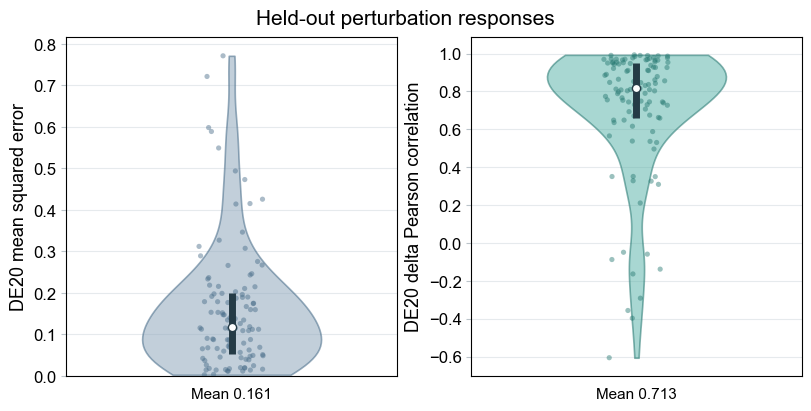

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
for ax, (metric, label, color, edge_color) in zip(axes, [
    ("mse_de20", "DE20 mean squared error", "#91A9BD", "#456A87"),
    ("pearson_delta_de20", "DE20 delta Pearson correlation", "#62B6AD", "#23766F"),
]):
    scores = evaluation.conditions[metric].to_numpy()
    violin = ax.violinplot(
        scores, positions=[0], widths=0.65,
        showmeans=False, showmedians=False, showextrema=False,
    )
    for body in violin["bodies"]:
        body.set_facecolor(color)
        body.set_edgecolor(edge_color)
        body.set_alpha(0.55)
        body.set_linewidth(1.2)
    jitter = np.random.default_rng(42).uniform(-0.12, 0.12, len(scores))
    ax.scatter(jitter, scores, s=14, color=edge_color, alpha=0.45, edgecolors="none", zorder=3)
    q1, median, q3 = np.quantile(scores, [0.25, 0.5, 0.75])
    ax.vlines(0, q1, q3, color="#253B46", linewidth=5, zorder=4)
    ax.scatter(0, median, s=35, color="white", edgecolor="#253B46", zorder=5)
    low, high = scores.min(), scores.max()
    padding = 0.06 * (high - low)
    ax.set_ylim(0 if low >= 0 else low - padding, high + padding)
    ax.set_ylabel(label, fontsize=13)
    ax.set_xticks([0], [f"Mean {scores.mean():.3f}"], fontsize=11)
    ax.set_xlim(-0.6, 0.6)
    ax.set_axisbelow(True)
    ax.yaxis.grid(True, color="#E6EAED", linewidth=0.8)
    ax.tick_params(axis="x", length=0, pad=8)
    ax.tick_params(axis="y", color="#BBC4CA", labelsize=12)
fig.suptitle("Held-out perturbation responses", fontsize=15)
plt.show()

### Inspect a single and a two-gene perturbation

DUSP9+ctrl and MAP2K6+SPI1 are fixed examples selected from the split before inspecting prediction scores. Each dot is one retained gene; teal highlights DE20 genes. The diagonal marks agreement. Every panel is 4×4 inches.

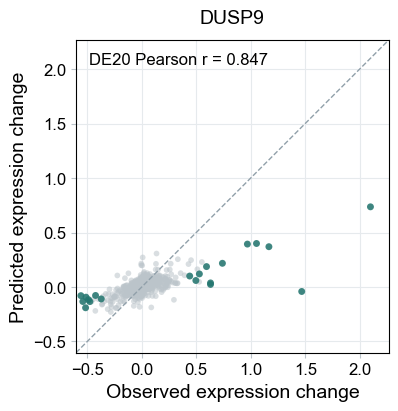

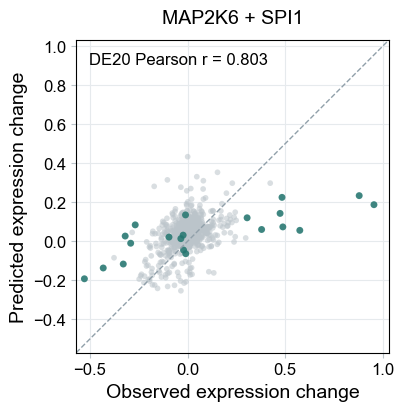

In [7]:
for condition in ["DUSP9+ctrl", "MAP2K6+SPI1"]:
    observed = np.asarray(test[test.obs["condition"] == condition].X.mean(axis=0)).ravel()
    observed_delta = observed - control_mean
    predicted_delta = predictions.mean_expression.loc[condition].to_numpy() - control_mean
    de_positions = train.var_names.get_indexer(de_genes[condition])
    fig, ax = plt.subplots(figsize=(4, 4), layout="constrained")
    ax.scatter(observed_delta, predicted_delta, s=17, color="#BBC4CA",
               alpha=0.55, edgecolors="none")
    ax.scatter(observed_delta[de_positions], predicted_delta[de_positions],
               s=25, color="#23766F", alpha=0.85, edgecolors="none")
    limits = np.array([
        min(observed_delta.min(), predicted_delta.min()),
        max(observed_delta.max(), predicted_delta.max()),
    ]) * 1.08
    ax.plot(limits, limits, color="#91A0AA", linewidth=1, linestyle="--")
    ax.set_xlim(limits)
    ax.set_ylim(limits)
    ax.set_aspect("equal", adjustable="box")
    correlation = evaluation.conditions.loc[condition, "pearson_delta_de20"]
    ax.text(0.04, 0.96, f"DE20 Pearson r = {correlation:.3f}",
            transform=ax.transAxes, ha="left", va="top", fontsize=12)
    ax.set_title(condition.replace("+ctrl", "").replace("+", " + "), fontsize=14, pad=12)
    ax.set_xlabel("Observed expression change", fontsize=14)
    ax.set_ylabel("Predicted expression change", fontsize=14)
    ax.tick_params(labelsize=12, color="#BBC4CA")
    ax.set_axisbelow(True)
    ax.grid(True, color="#E6EAED", linewidth=0.8)
    plt.show()

## 6. Optional: save the predictor and evaluation tables

Export is disabled by default. When enabled, this saves the selected predictor and its prediction and evaluation tables. Checkpoints retain the averaged EFM gene embeddings, gene/ontology axes, tokenizer configuration and validation history. Figures remain inline.

Reload with `GenePerturbationPredictor.from_checkpoint(path, model_source=MODEL_SOURCE)`. Apply the same source expression scale and selected genes before prediction; checkpoint loading does not normalize raw data.

For long runs, `fit(training_checkpoint=...)` saves recovery state after each epoch. Use `resume_from=` with the same inputs and settings to continue training. Recovery inputs include the learning-rate schedule and early-stopping patience; resume with the same settings.

In [8]:
SAVE_RESULTS = False
if SAVE_RESULTS:
    output_dir = REPO_ROOT / "results" / "gene_perturbation_tutorial"
    output_dir.mkdir(parents=True, exist_ok=True)
    predictor.save_checkpoint(output_dir / "efm_gears.pt")
    for name, table in [
        ("summary", summary),
        ("predictions", predictions.to_expression_table()),
        ("per_condition", evaluation.to_condition_table()),
    ]:
        with (output_dir / f"{name}.csv").open("x") as handle:
            table.to_csv(handle)

The decoder is adapted from [GEARS](https://github.com/snap-stanford/GEARS). The deliberate upstream change replaces GEARS's learned gene embeddings with frozen EFM gene embeddings averaged over training controls; using foundation-model gene representations in GEARS follows [scFoundation](https://github.com/biomap-research/scFoundation/tree/main/GEARS). The adapted model source retains the complete GEARS copyright and MIT notice. Cite [Norman et al.](https://doi.org/10.1126/science.aax4438), [GSE133344](https://www.ncbi.nlm.nih.gov/geo/query/acc.cgi?acc=GSE133344), GEARS and scCAFM.